#### Business report
1. Product Categories

Sports & Outdoors dominates the catalogue, representing 83.1% of listings among the top 10 categories (836,265 products).

Business implication: This concentration suggests an uneven product distribution. Category balance and data representativeness should be checked before making inventory or market-demand decisions.

2. Product Pricing

The average price is £89.24, but the median is only £19.09. Half of all products cost between £9.99 and £45.99, while extreme prices reach approximately £100,000.

Business implication: The market shows a strong concentration of lower-priced listings. Businesses should use median prices and price segments rather than averages when benchmarking competitors and developing pricing strategies.

3. Product Ratings

Product ratings are generally high, averaging 4.32 stars, with 4.5 being the most common rating. Variation is relatively low (SD = 0.56).

Business implication: High ratings are common, making positive reviews alone a potentially weak differentiator. Businesses should also evaluate review volume, pricing, and product positioning.

##### Key Business Takeaways

- Category strategy: Validate the unusually high category concentration before interpreting listing volume as demand.

- Pricing strategy: Benchmark against realistic price segments, not averages distorted by expensive outliers.

- Competitive positioning: Combine customer ratings with other performance indicators to identify meaningful competitive advantages.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df_amazon = pd.read_csv("C:/Users/yurii/Downloads/IH_Labs/week5/amz_uk_price_prediction_dataset.csv")

#### Part 1

In [4]:
df_amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
df_amazon["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [8]:
df_amazon["category"].nunique()

296

In [10]:
df_amazon["category"].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [11]:
top_10 = df_amazon["category"].value_counts().head(10)

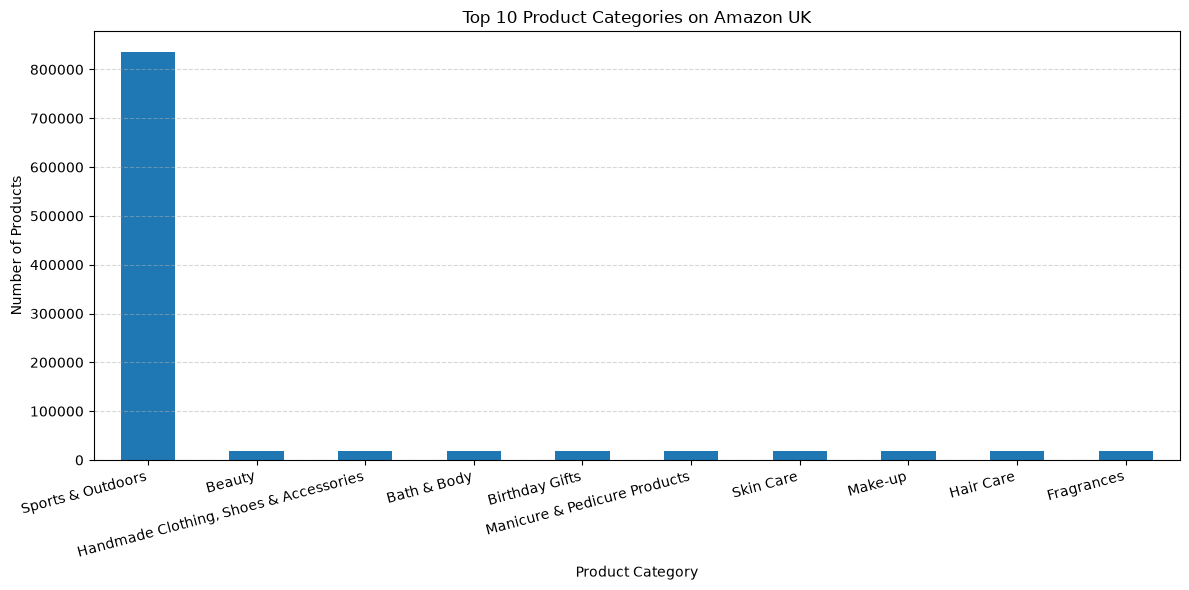

In [26]:
plt.figure(figsize=(12, 6))
top_10.plot(kind="bar")

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

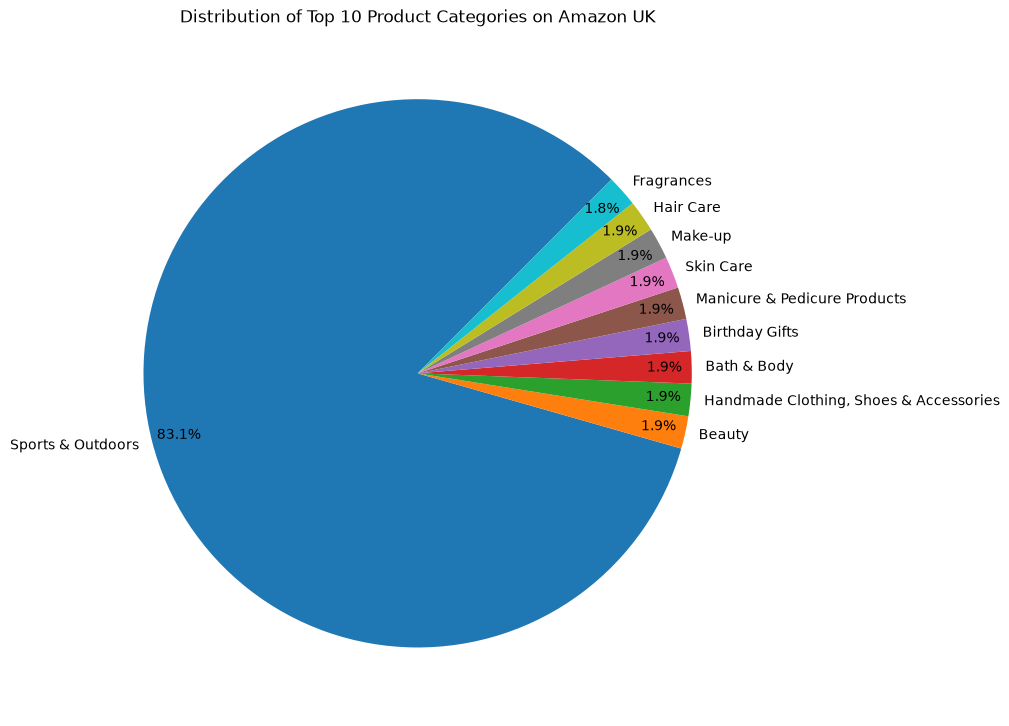

In [41]:
plt.figure(figsize=(10, 10))

plt.pie(
    top_10,
    labels=top_10.index,
    autopct="%1.1f%%",
    startangle=45,
    pctdistance=0.9,
    labeldistance=1.05
)

plt.title("Distribution of Top 10 Product Categories on Amazon UK")
plt.tight_layout()
plt.show()

##### Sports & Outdoors dominates the listings a lot

#### Part 2

In [45]:
df_amazon[["title", "price"]].head(10)

,title,price
0,"Echo Dot (5th generation, 2022 release) | Big ...",21.99
1,"Anker Soundcore mini, Super-Portable Bluetooth...",23.99
2,"Echo Dot (5th generation, 2022 release) | Big ...",21.99
3,"Echo Dot with clock (5th generation, 2022 rele...",31.99
4,Introducing Echo Pop | Full sound compact Wi-F...,17.99
5,"Echo Dot with clock (5th generation, 2022 rele...",31.99
6,"Echo Dot (5th generation, 2022 release) | Big ...",21.99
7,Anker Soundcore 2 Portable Bluetooth Speaker w...,39.99
8,"Bluetooth Speaker, Anker Soundcore Speaker Upg...",29.99
9,RIENOK Bluetooth Speaker Portable Wireless Blu...,29.99


In [47]:
df_amazon["price"].mean().round(2)

np.float64(89.24)

In [48]:
df_amazon["price"].median()

np.float64(19.09)

In [49]:
df_amazon["price"].mode()

0    9.99
Name: price, dtype: float64

#### The price distribution appears right-skewed. The mean price (£89.24) is substantially higher than the median (£19.09), suggesting that high-priced products pull the average upward. The most common listed price is £9.99.

In [51]:
df_amazon["price"].var().round(2)

np.float64(119445.49)

In [53]:
df_amazon["price"].std().round(2)

np.float64(345.61)

In [54]:
df_amazon["price"].max() - df_amazon["price"].min()

np.float64(100000.0)

In [55]:
df_amazon["price"].quantile(0.25)  # Q1
df_amazon["price"].quantile(0.75)  # Q3

np.float64(45.99)

In [56]:
df_amazon["price"].quantile(0.75) - df_amazon["price"].quantile(0.25)

np.float64(36.0)

##### Product prices show significant variation. The standard deviation (£345.61) is much higher than the mean (£89.24), while the total range reaches £100,000. However, the IQR is only £36, indicating that the middle 50% of products are concentrated within a relatively narrow price range. Extreme high-priced products significantly increase the overall price dispersion.

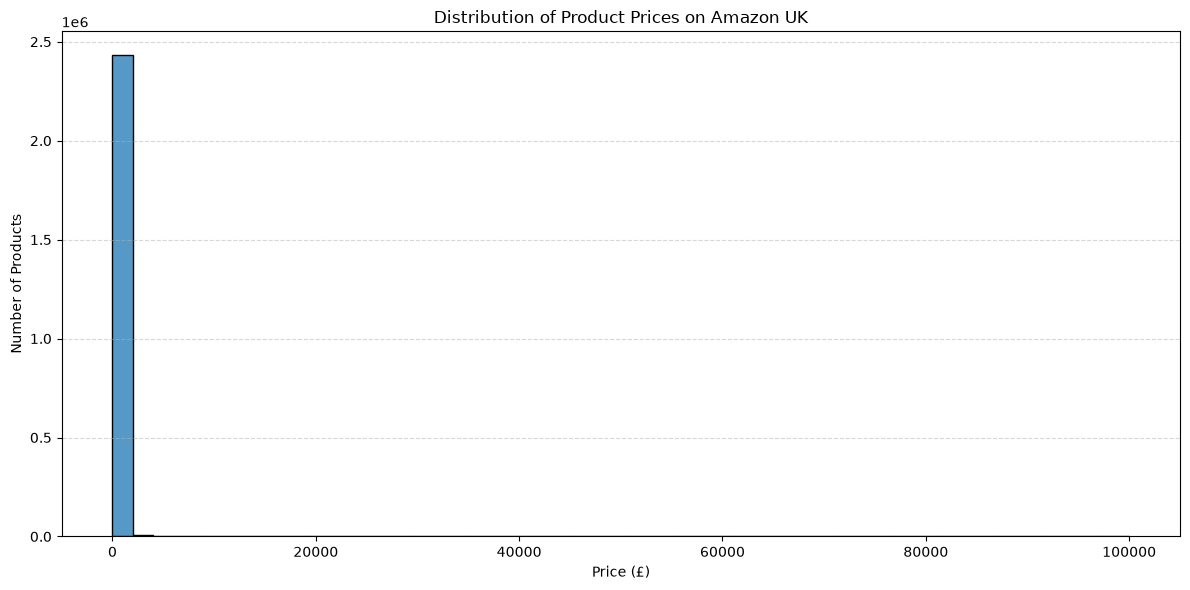

In [57]:
plt.figure(figsize=(12, 6))

sns.histplot(data=df_amazon, x="price", bins=50)

plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Check the prices below which 50%, 75%, 90%, 95%, 99% of products fall, to choose a good range for chart
df_amazon["price"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])

0.50      19.09
0.75      45.99
0.90     149.99
0.95     349.50
0.99    1408.82
Name: price, dtype: float64

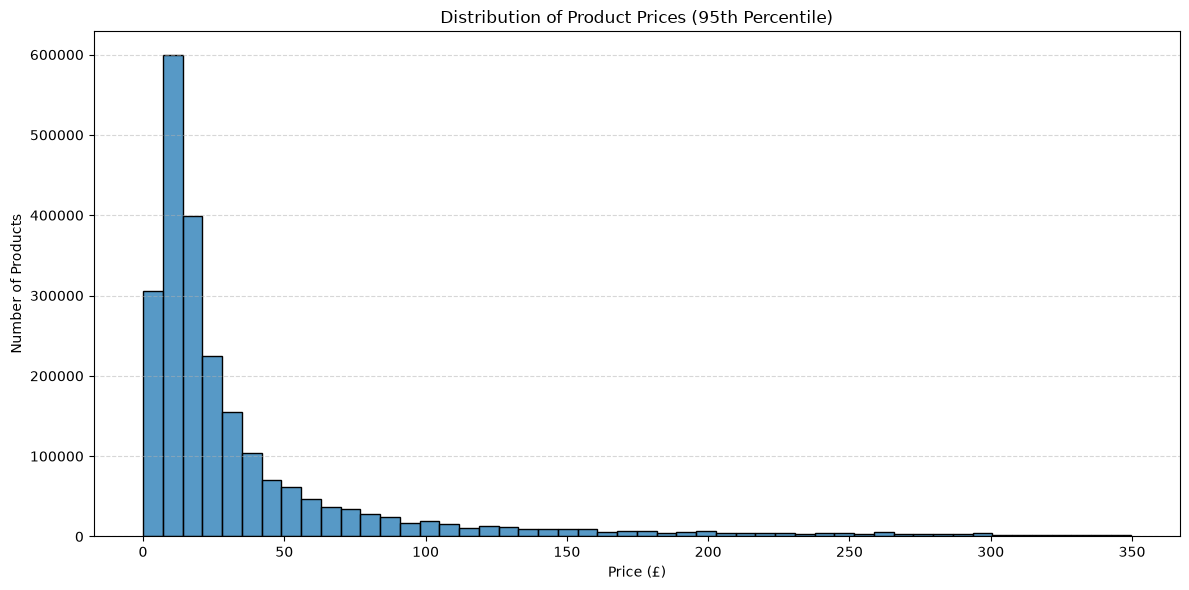

In [60]:
# Calculate the 95th percentile
price_limit = df_amazon["price"].quantile(0.95)

# Filter data for visualization
prices_filtered = df_amazon[df_amazon["price"] <= price_limit]

# Histogram
plt.figure(figsize=(12, 6))

sns.histplot(data=prices_filtered, x="price", bins=50)

plt.title("Distribution of Product Prices (95th Percentile)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

##### Extreme prices make the original histogram difficult to read. Using the 95th percentile as a cutoff helps me better visualize where most product prices are concentrated (below £349.50)

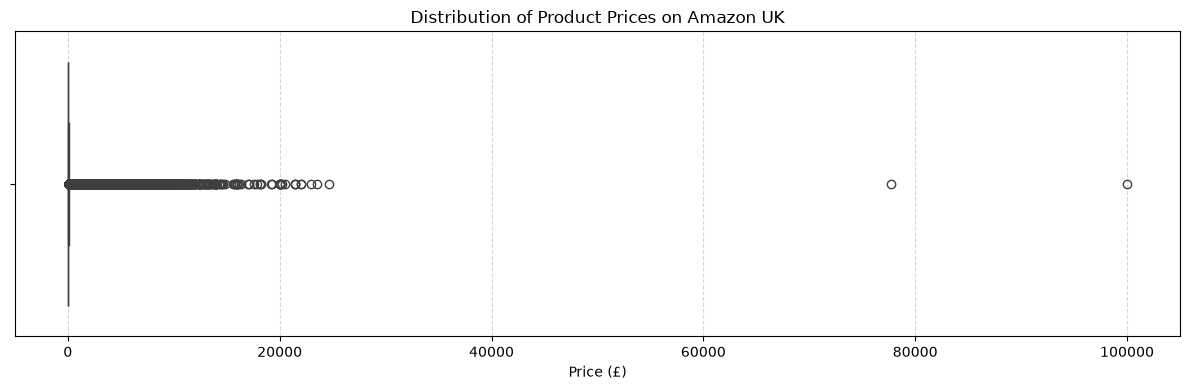

In [ ]:
# boxplot for all existing prices

plt.figure(figsize=(12, 4))

sns.boxplot(data=df_amazon, x="price")

plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

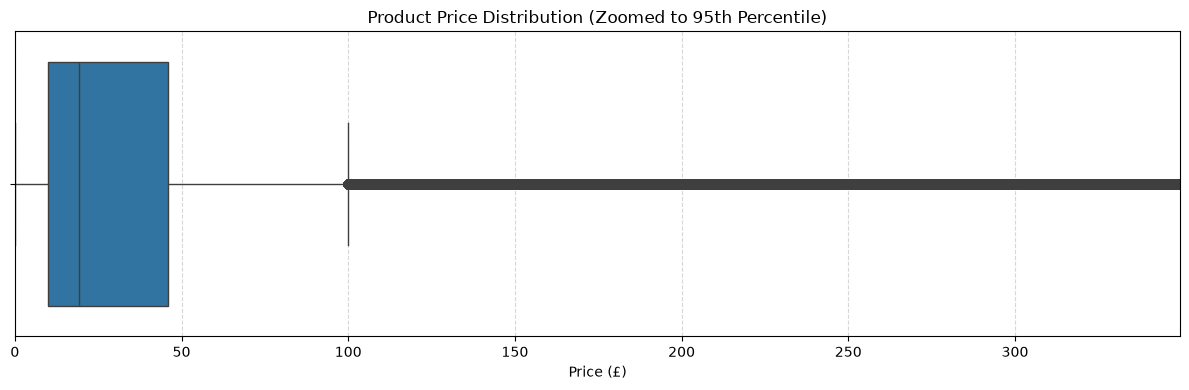

In [62]:
# 95th percentile (£349.50)

price_limit = df_amazon["price"].quantile(0.95)

plt.figure(figsize=(12, 4))

sns.boxplot(data=df_amazon, x="price")

plt.title("Product Price Distribution (Zoomed to 95th Percentile)")
plt.xlabel("Price (£)")
plt.xlim(0, price_limit)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

##### Most products are concentrated in a low price range, with 50% priced between £9.99 and £45.99. The box plot reveals numerous high-price outliers above £99.99. Product prices are strongly right-skewed, with expensive products creating a significant spread in the distribution.

#### Part 3

In [63]:
df_amazon["stars"].head(10)

0    4.7
1    4.7
2    4.7
3    4.7
4    4.6
5    4.7
6    4.7
7    4.7
8    4.7
9    4.5
Name: stars, dtype: float64

In [64]:
ratings = df_amazon.loc[df_amazon["stars"].between(1, 5), "stars"]

In [67]:
mean_rating = ratings.mean()
mean_rating.round(2)

np.float64(4.32)

In [68]:
median_rating = ratings.median()
median_rating

np.float64(4.4)

In [70]:
mode_rating = ratings.mode().iloc[0]
mode_rating

np.float64(4.5)

##### Product ratings are generally high, with a mean of 4.32, a median of 4.4, and the most common rating of 4.5 stars. Customers tend to rate products positively, with typical ratings above 4 stars.

In [72]:
variance_rating = ratings.var()
variance_rating.round(2)

np.float64(0.31)

In [74]:
std_rating = ratings.std()
std_rating.round(2)

np.float64(0.56)

In [75]:
iqr_rating = ratings.quantile(0.75) - ratings.quantile(0.25)
iqr_rating

np.float64(0.5)

##### Product ratings show relatively low variation, with a standard deviation of 0.56 and an IQR of 0.5 stars. Customer ratings are generally consistent, with most products receiving similarly high ratings.

In [77]:
skewness_rating = ratings.skew()
skewness_rating.round(2)

np.float64(-2.38)

In [79]:
kurtosis_rating = ratings.kurt()
kurtosis_rating.round(2)

np.float64(9.78)

##### Product ratings are strongly left-skewed (skewness = -2.38), meaning most products receive high ratings, while relatively few have low ratings. The high kurtosis (9.78) indicates heavy tails and more extreme observations than a normal distribution. Ratings are not normally distributed and are heavily concentrated toward higher values.

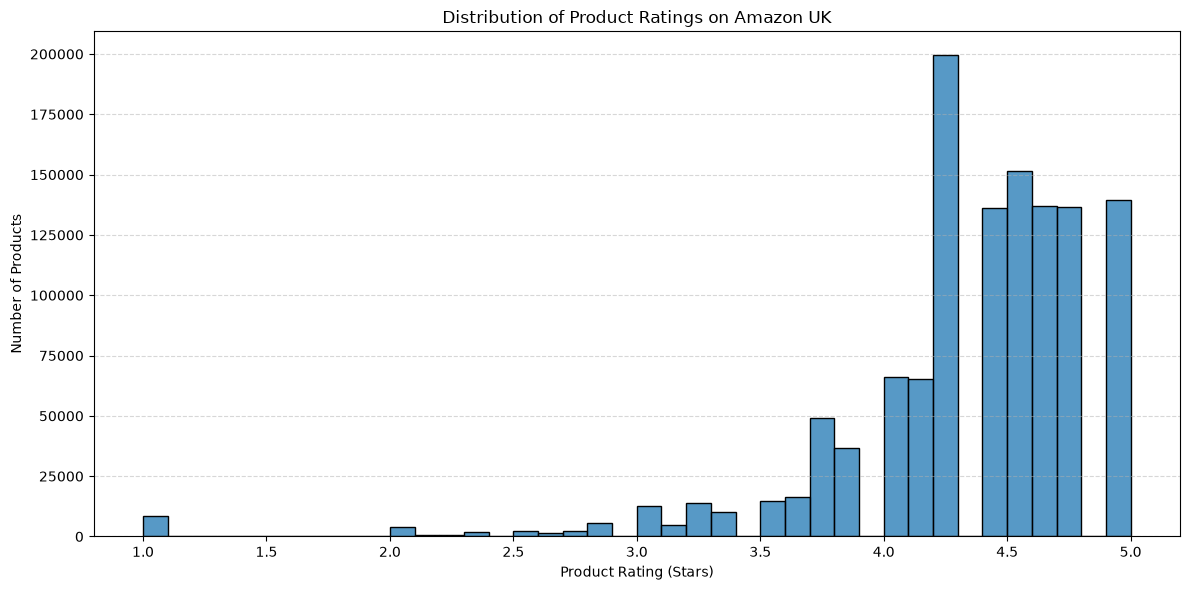

In [80]:
plt.figure(figsize=(12, 6))

sns.histplot(ratings, bins=40)

plt.title("Distribution of Product Ratings on Amazon UK")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Number of Products")
plt.xticks(np.arange(1, 5.1, 0.5))
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

##### Product ratings are concentrated toward higher values, with the most common rating being 4.5 stars. The mean rating is 4.32, confirming generally positive customer feedback. Most rated products receive high ratings, while low ratings are relatively uncommon. The distribution is strongly left-skewed.